In [1]:
import numpy as np
from sklearn.datasets import load_iris 
from sklearn.linear_model import Perceptron 

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = (iris.target == 0)

per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

X_new = [[2, 0.5], [3, 1]]
y_pred = per_clf.predict(X_new)

In [2]:
y_pred

array([ True, False])

In [3]:
y

0       True
1       True
2       True
3       True
4       True
       ...  
145    False
146    False
147    False
148    False
149    False
Name: target, Length: 150, dtype: bool

In [4]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)




In [5]:
rmse

0.5053326657968684

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

dummy = make_pipeline(
    StandardScaler(),
    DummyRegressor(strategy="mean")
)

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_valid)

dummy_rmse = root_mean_squared_error(y_valid, dummy_pred)

print("Baseline rmse : ", dummy_rmse)
print("Neural Network rmse : ", rmse)

Baseline rmse :  1.1476260241965577
Neural Network rmse :  0.5053326657968684


In [7]:
from sklearn.ensemble import RandomForestRegressor

rfr = make_pipeline(
    StandardScaler(),
    RandomForestRegressor(random_state=42)
)

rfr.fit(X_train, y_train)

rfr_pred = rfr.predict(X_valid)

rfr_rmse = root_mean_squared_error(y_valid, rfr_pred)

print("Random Forest rmse: ", rfr_rmse)

Random Forest rmse:  0.5073847566107056


In [8]:
from sklearn.neural_network import MLPClassifier

iris = load_iris()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlpc = MLPClassifier(hidden_layer_sizes=[5])

pipeline = make_pipeline(StandardScaler(),
                         mlpc
)

pipeline.fit(X_train, y_train)

mlpc_pred = pipeline.predict(X_valid)

mlpc_rmse  = root_mean_squared_error(y_valid, mlpc_pred)
print("MLPClassifier rmse : ", mlpc_rmse)

MLPClassifier rmse :  1.1801936887041646


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [9]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, mlpc_pred)

print("MLPClassifier Accuracy:", accuracy)

MLPClassifier Accuracy: 0.35714285714285715


In [10]:
from sklearn.neural_network import MLPClassifier

iris = load_iris()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlpc = MLPClassifier(hidden_layer_sizes=[10])

pipeline = make_pipeline(StandardScaler(),
                         mlpc
)

pipeline.fit(X_train, y_train)

mlpc_pred = pipeline.predict(X_valid)

mlpc_rmse  = root_mean_squared_error(y_valid, mlpc_pred)
print("MLPClassifier rmse : ", mlpc_rmse)

MLPClassifier rmse :  0.3779644730092272


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, mlpc_pred)

print("MLPClassifier Accuracy:", accuracy)

MLPClassifier Accuracy: 0.8571428571428571


In [12]:
import tensorflow as tf 

fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist 
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

I0000 00:00:1794211100.800404   27809 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [13]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (55000, 28, 28) (55000,)
Validation: (5000, 28, 28) (5000,)
Testing: (10000, 28, 28) (10000,)


In [14]:
X_train, X_valid, X_test = (
    X_train / 255. ,
    X_valid / 255. ,
    X_test / 255. 
)

In [15]:
print(X_train.min())
print(X_train.max())
print(X_train.dtype)

0.0
1.0
float64


In [16]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker","Bag", "Ankle boot"]

In [17]:
class_names[y_train[8]]

'Sandal'

In [18]:
class_names[y_train[4]]

'T-shirt/top'

In [19]:
tf.random.set_seed(42)

model = tf.keras.Sequential()

model.add(tf.keras.layers.Input(shape=[28, 28]))

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(300,activation="relu"))

model.add(tf.keras.layers.Dense(100,activation="relu"))

model.add(tf.keras.layers.Dense(10,activation="softmax"))
 

W0000 00:00:1794211107.053864   27809 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [20]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

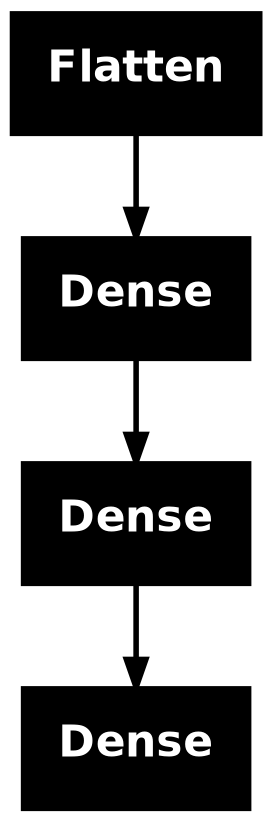

In [22]:
tf.keras.utils.plot_model(model)

In [23]:
model.layers

[<Flatten name=flatten_1, built=True>,
 <Dense name=dense_3, built=True>,
 <Dense name=dense_4, built=True>,
 <Dense name=dense_5, built=True>]

In [24]:
hidden1 = model.layers[1]

In [25]:
hidden1

<Dense name=dense_3, built=True>

In [26]:
model.get_layer('dense_3') is hidden1

True

In [27]:
weights, biases = hidden1.get_weights()

In [28]:
weights

array([[ 0.02202252,  0.04530741,  0.01941889, ...,  0.0230675 ,
        -0.01766898, -0.03538464],
       [-0.05834266,  0.05010135,  0.07235941, ..., -0.06210998,
        -0.01070744, -0.00376117],
       [ 0.05467436,  0.06272128, -0.00393819, ...,  0.02963637,
        -0.02343286, -0.06774119],
       ...,
       [-0.00775006, -0.04192161,  0.04108576, ..., -0.04374532,
         0.03927375,  0.00262737],
       [ 0.00846218, -0.00710186, -0.01950763, ..., -0.020252  ,
         0.04941805, -0.06268448],
       [-0.0385892 ,  0.01719999,  0.01899577, ..., -0.06818058,
         0.05315515,  0.06025507]], shape=(784, 300), dtype=float32)

In [29]:
weights.shape


(784, 300)

In [30]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [31]:
biases.shape

(300,)

In [32]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="sgd",
              metrics=["accuracy"])

In [34]:
history = model.fit(X_train, y_train, epochs=30,
                    validation_data=(X_valid, y_valid))

Epoch 1/30


W0000 00:00:1794211554.050457   27809 cpu_allocator_impl.cc:82] Allocation of 172480000 exceeds 10% of free system memory.


1696/1719 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7633 - loss: 0.7147

W0000 00:00:1794211558.309625   27809 cpu_allocator_impl.cc:82] Allocation of 15680000 exceeds 10% of free system memory.


1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7638 - loss: 0.7123 - val_accuracy: 0.8256 - val_loss: 0.5084
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8310 - loss: 0.4852 - val_accuracy: 0.8368 - val_loss: 0.4546
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8463 - loss: 0.4404 - val_accuracy: 0.8462 - val_loss: 0.4294
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8549 - loss: 0.4130 - val_accuracy: 0.8534 - val_loss: 0.4146
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8613 - loss: 0.3932 - val_accuracy: 0.8568 - val_loss: 0.4029
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8662 - loss: 0.3776 - val_accuracy: 0.8580 - val_loss: 0.3941
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8703 - loss: 0.3643 - val_accuracy: 0.8616 - val_loss: 0.3847
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8749 - loss: 0.3525 - val_accurac